Лабораторная работа №1: регрессия.

Импортирую нужные для чтения и обработки данных библиотеки.

In [130]:
%pip install -q ucimlrepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from ucimlrepo import fetch_ucirepo

Беру датасет из UCI Repository прямо по айди, без ручного скачивания CSV.
Создаю объект DataFrame, вывожу размеры, типы столбцов и непустые значения, число уникальных значений в каждом столбце и первые пять строк. 

In [131]:
wine = fetch_ucirepo(id=186)
df = wine.data.original

print(df.shape)
df.info()
print('Unique:')
print(df.nunique())
df.head()

(6497, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB
Unique:
fixed_acidity           106
volatile_acidity

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


Вывод. Датасет содержит 6497 вин (красные и белые), 11 непрерывных физико-химических признаков, целевую переменную quality и категориальный признак color. Пропусков нет, поэтому импутация не требуется. Признак color хранится как строка и перед обучением должен быть закодирован в бинарный вид. Целевая переменная принимает лишь 7 различных значений, то есть крайние оценки шкалы 0–10 в данных отсутствуют, и модель не сможет их предсказывать. Признаки измерены с ограниченной точностью и имеют мало уникальных значений, что повышает вероятность повторяющихся строк, поэтому следующим шагом проверим дубликаты.

Проверю наличие дубликатов и выведу их.

In [132]:
print('Число дубликатов:', df.duplicated().sum())
print('По цвету:', df[df.duplicated()]['color'].value_counts().to_dict())
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

Число дубликатов: 1177
По цвету: {'white': 937, 'red': 240}


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
6270,4.9,0.335,0.14,1.3,0.036,69.0,168.0,0.99212,3.47,0.46,10.466667,5,white
6271,4.9,0.335,0.14,1.3,0.036,69.0,168.0,0.99212,3.47,0.46,10.466667,5,white
5540,4.9,0.345,0.34,1.0,0.068,32.0,143.0,0.99138,3.24,0.40,10.100000,5,white
5549,4.9,0.345,0.34,1.0,0.068,32.0,143.0,0.99138,3.24,0.40,10.100000,5,white
4589,5.0,0.270,0.32,4.5,0.032,58.0,178.0,0.98956,3.45,0.31,12.600000,7,white
4606,5.0,0.270,0.32,4.5,0.032,58.0,178.0,0.98956,3.45,0.31,12.600000,7,white
2802,5.0,0.330,0.16,1.5,0.049,10.0,97.0,0.99170,3.48,0.44,10.700000,6,white
2803,5.0,0.330,0.16,1.5,0.049,10.0,97.0,0.99170,3.48,0.44,10.700000,6,white
2812,5.0,0.330,0.16,1.5,0.049,10.0,97.0,0.99170,3.48,0.44,10.700000,6,white
6043,5.0,0.350,0.25,7.8,0.031,24.0,116.0,0.99241,3.39,0.40,11.300000,6,white


Вывод. В датасете около 1177 полных дубликатов, то есть почти 18% строк, причём большинство приходится на белые вина. Копии совпадают по всем признакам и по оценке качества, поэтому новой информации не несут. Если оставить их, при случайном разбиении одинаковые вина попадут и в обучающую, и в тестовую выборку, и оценка качества модели окажется завышенной (утечка данных). Поэтому удаляем дубликаты до разбиения. После удаления остаётся около 5320 уникальных вин, этого по-прежнему достаточно для обучения.

In [133]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(5320, 13)


Исследую выбросы в датасете и сравню красные и белые вина.

In [134]:
display(df.describe().T)
df.groupby('color').mean(numeric_only=True).T

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,5320.0,7.215179,1.319671,3.80000,6.4000,7.00000,7.70000,15.90000
volatile_acidity,5320.0,0.344130,0.168248,0.08000,0.2300,0.30000,0.41000,1.58000
citric_acid,5320.0,0.318494,0.147157,0.00000,0.2400,0.31000,0.40000,1.66000
residual_sugar,5320.0,5.048477,4.500180,0.60000,1.8000,2.70000,7.50000,65.80000
chlorides,5320.0,0.056690,0.036863,0.00900,0.0380,0.04700,0.06600,0.61100
free_sulfur_dioxide,5320.0,30.036654,17.805045,1.00000,16.0000,28.00000,41.00000,289.00000
total_sulfur_dioxide,5320.0,114.109023,56.774223,6.00000,74.0000,116.00000,153.25000,440.00000
density,5320.0,0.994535,0.002966,0.98711,0.9922,0.99465,0.99677,1.03898
pH,5320.0,3.224664,0.160379,2.72000,3.1100,3.21000,3.33000,4.01000
sulphates,5320.0,0.533357,0.149743,0.22000,0.4300,0.51000,0.60000,2.00000


color,red,white
fixed_acidity,8.310596,6.839346
volatile_acidity,0.529478,0.280538
citric_acid,0.272333,0.334332
residual_sugar,2.523400,5.914819
chlorides,0.088124,0.045905
free_sulfur_dioxide,15.893304,34.889169
total_sulfur_dioxide,46.825975,137.193512
density,0.996709,0.993790
pH,3.309787,3.195458
sulphates,0.658705,0.490351


Вывод. После удаления дубликатов осталось 5320 вин. Признаки имеют очень разные масштабы (std плотности ≈ 0,003, std общего диоксида серы ≈ 57), поэтому для моделей, чувствительных к масштабу (kNN, SVM, линейные модели с регуляризацией), потребуется стандартизация. У residual_sugar, chlorides, free_sulfur_dioxide, total_sulfur_dioxide и sulphates максимум в 3–9 раз превышает 75-й перцентиль, а среднее заметно больше медианы: распределения скошены вправо и содержат выбросы. Для линейных моделей эти признаки стоит логарифмировать. Алкоголь и pH распределены почти симметрично.

Целевая переменная принимает значения от 3 до 9, половина вин имеет оценку 5 или 6. Стандартное отклонение качества 0,88 задаёт базовый уровень: модель, предсказывающая среднее, ошибается примерно на 0,88 балла, и наши модели должны быть заметно точнее.

Красные и белые вина существенно различаются по составу: у красных почти вдвое выше летучая кислотность и хлориды, у белых втрое больше диоксида серы и вдвое больше сахара. Средняя оценка у белых немного выше. Поскольку цвет связан и с признаками, и с качеством, на объединённых данных возможны ложные зависимости. Поэтому color включаем в модель как признак, а связи признаков с качеством дополнительно проверяем отдельно для каждого цвета.

Проверяю, сколько вин получило каждую оценку, и одинаковы ли эти значения у красных и белых вин.

,count
quality,
3,30
4,206
5,1752
6,2323
7,856
8,148
9,5


color,red,white,All
quality,,,
3,10,20,30
4,53,153,206
5,577,1175,1752
6,535,1788,2323
7,167,689,856
8,17,131,148
9,0,5,5
All,1359,3961,5320


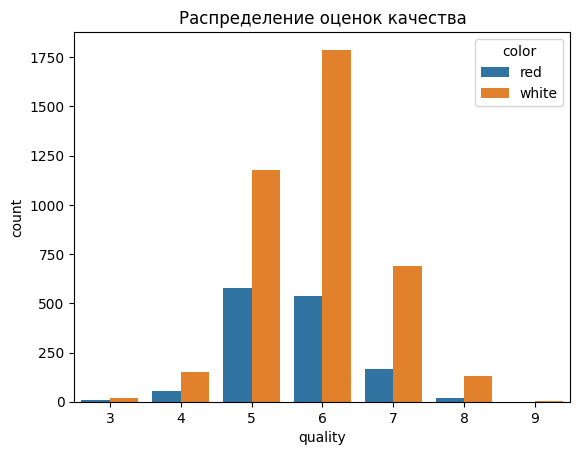

In [135]:
display(df['quality'].value_counts().sort_index())
display(pd.crosstab(df['quality'], df['color'], margins=True))
sns.countplot(data=df, x='quality', hue='color')
plt.title('Распределение оценок качества')
plt.show()

Вывод. Целевая переменная сильно несбалансирована: около 77% вин получили оценки 5 или 6, а вместе с оценкой 7 — около 93%. Крайние оценки редки (оценка 3 у 30 вин, оценка 9 всего у 5), а оценки 0–2 и 10 отсутствуют. Из-за этого модель будет склонна предсказывать значения близкие к 5–6 и хуже всего справляться с очень плохими и отличными винами. Поэтому, помимо общей метрики, будем анализировать ошибку отдельно по оценкам, а при разбиении на обучающую и тестовую выборки использовать стратификацию по quality. Поскольку оценки упорядочены, задачу естественно решать как регрессию.

Распределения оценок у красных и белых вин различаются: у красных мода равна 5, у белых — 6. Оценка 9 встречается только у белых вин, а красных вин с оценкой 8 почти нет. Белых вин примерно втрое больше, поэтому на объединённых данных их закономерности будут преобладать. Это ещё один аргумент в пользу включения color в модель.

Изучу распределения признаков: построю гистограммы и посчитаю коэффициент асимметрии, чтобы найти скошенные признаки — кандидатов на логарифмирование.

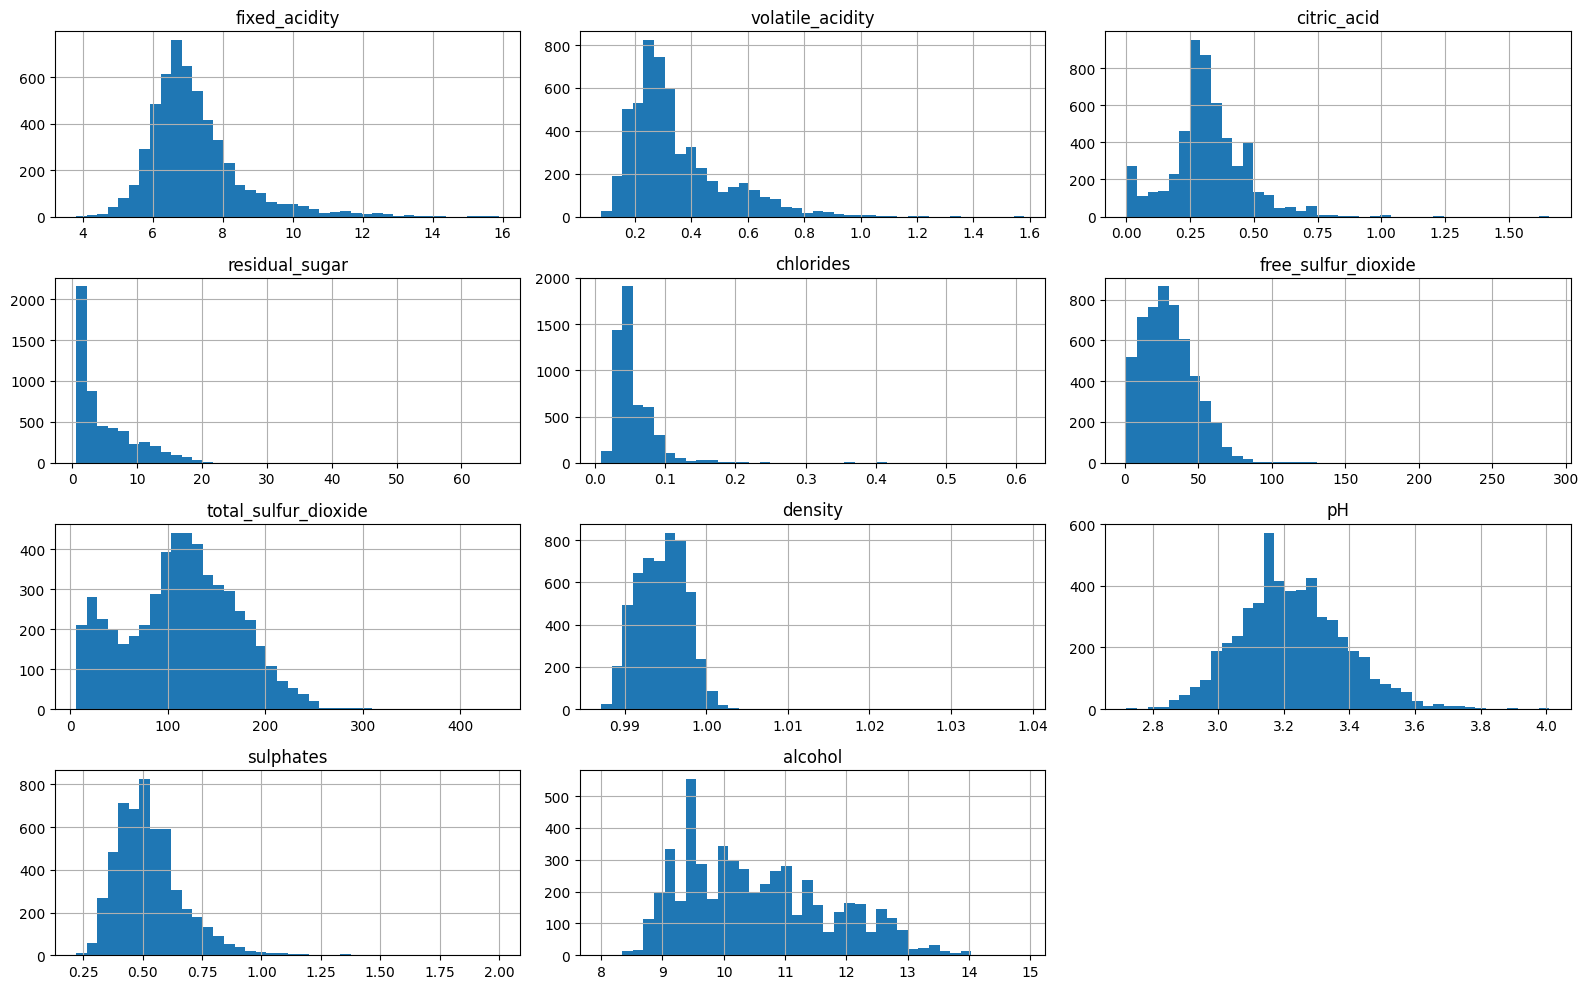

,skew
chlorides,5.338237
sulphates,1.809454
residual_sugar,1.706550
fixed_acidity,1.650417
volatile_acidity,1.504557
free_sulfur_dioxide,1.362719
density,0.666326
alcohol,0.545696
citric_acid,0.484309
pH,0.389969


In [136]:
features = df.columns.drop(['quality', 'color'])

df[features].hist(bins=40, figsize=(16, 10))
plt.tight_layout()
plt.show()

display(df[features].skew().sort_values(ascending=False).to_frame('skew'))

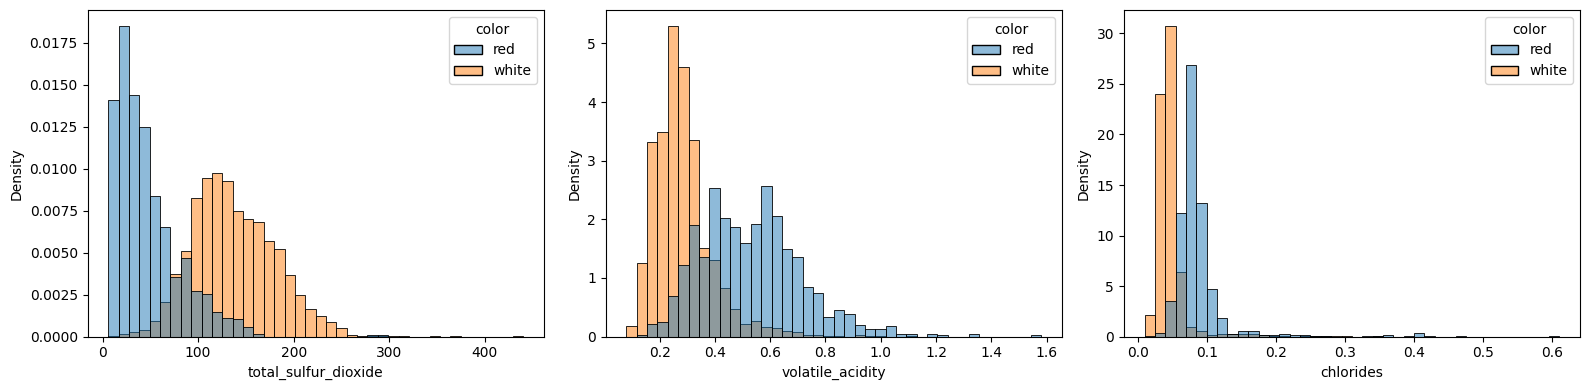

In [137]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['total_sulfur_dioxide', 'volatile_acidity', 'chlorides']):
    sns.histplot(data=df, x=col, hue='color', bins=40, ax=ax, stat='density', common_norm=False)
plt.tight_layout()
plt.show()

Вывод. Шесть признаков имеют сильный скос вправо (skew > 1): chlorides (5,3), sulphates, residual_sugar, fixed_acidity, volatile_acidity, free_sulfur_dioxide (1,4–1,8). Основная масса вин сосредоточена в области малых значений, а редкие вина образуют длинный хвост. Для линейных моделей эти признаки логарифмируем (log1p), чтобы снизить влияние экстремальных значений. density и alcohol скошены умеренно, pH и citric_acid почти симметричны, их оставляем как есть.

Разбивка по цвету показала, что часть асимметрии создаётся смешением двух популяций. У total_sulfur_dioxide коэффициент асимметрии близок к нулю (0,06), однако распределение двугорбое: у красных вин типичное значение 20–40, у белых около 120. Это пример того, что skew не отражает многомодальность и его нужно проверять графиком. Аналогично у volatile_acidity и chlorides распределения красных сдвинуты вправо, а длинный хвост хлоридов почти полностью образован красными винами.

Следовательно, цвет вина определяет типичный уровень сразу нескольких признаков: одно и то же значение может быть нормой для красного вина и аномалией для белого. Поэтому color обязательно включаем в модель. Если линейная модель окажется недостаточно точной, стоит попробовать обучить отдельные модели для красных и белых вин или использовать модели, способные учитывать взаимодействия признаков (деревья, бустинг).

Исследую датасет на выбросы: для этого выведу ящик с усами.

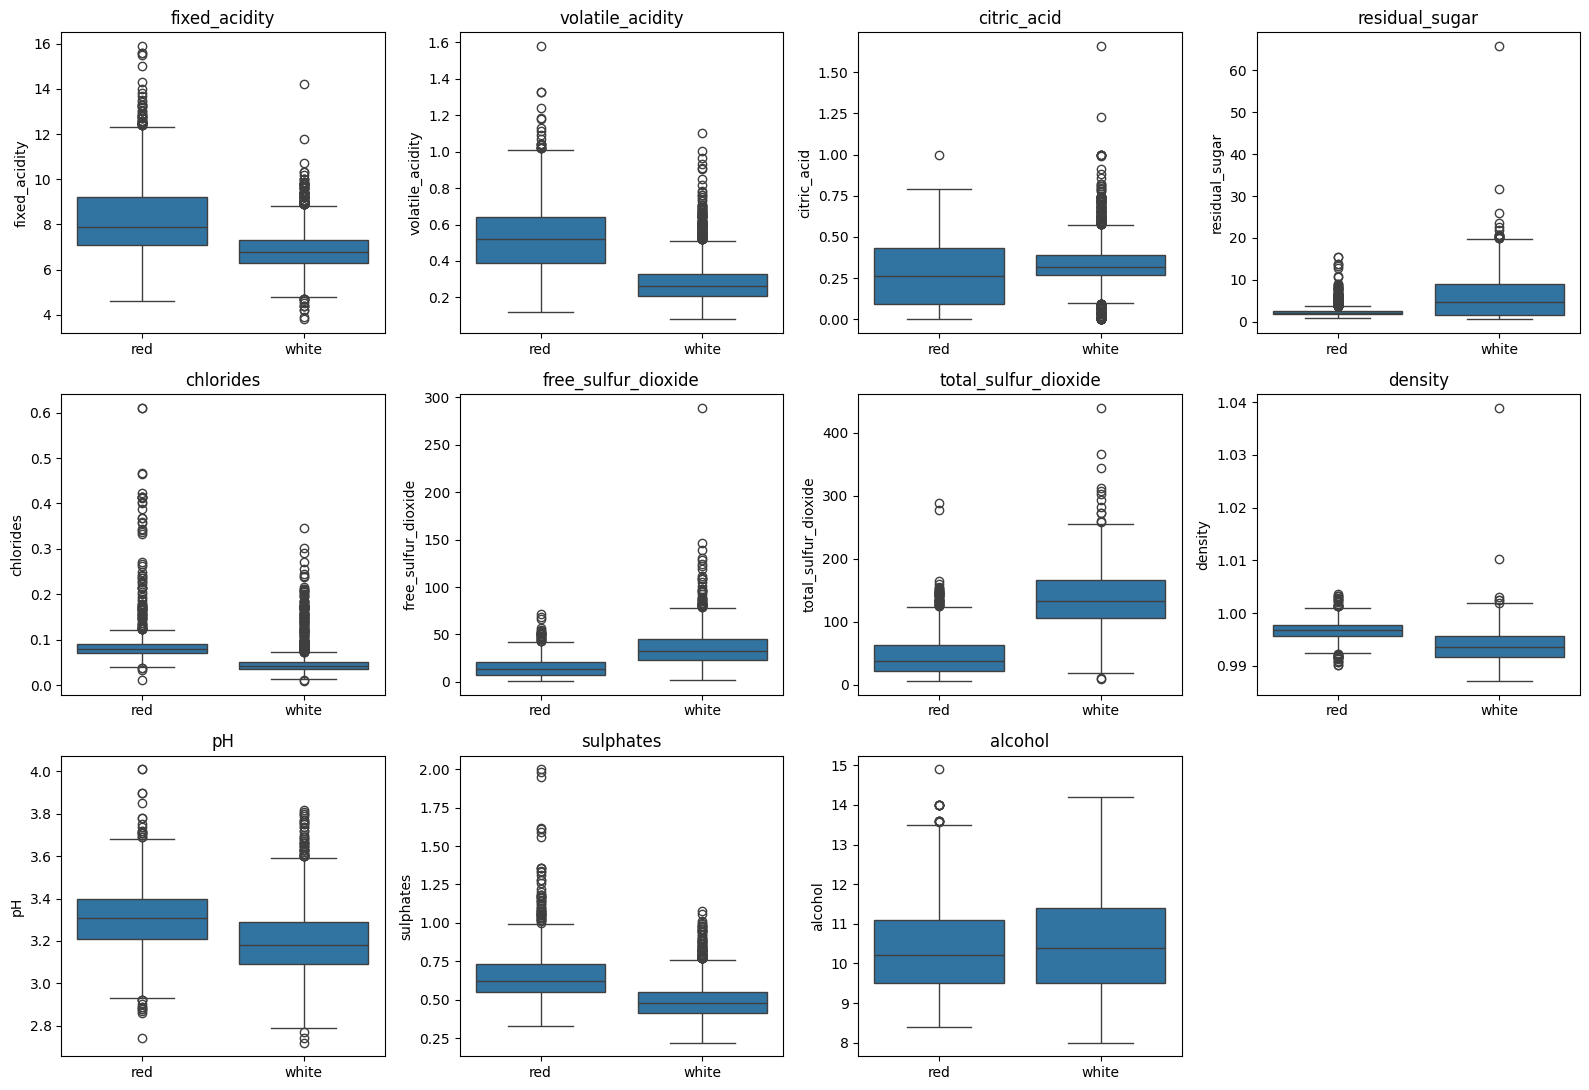

In [138]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x='color', y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

На графиках chlorides, free_sulfur_dioxide, density и residual_sugar отлично видно аномалии - отдельные кружочки лежат слишком далеко от 'усов'. Выведем эти вина

In [139]:
display(df.nlargest(2, 'density'))
display(df.nlargest(2, 'residual_sugar'))
display(df.nlargest(2, 'total_sulfur_dioxide'))
display(df.nlargest(2, 'free_sulfur_dioxide'))
display(df.nlargest(2, 'chlorides'))
display(df.nlargest(2, 'volatile_acidity'))
display(df.nlargest(2, 'alcohol'))
display(df.nlargest(2, 'citric_acid'))

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
3653,7.8,0.965,0.60,65.8,0.074,8.0,160.0,1.03898,3.39,0.69,11.7,6,white
2753,7.9,0.330,0.28,31.6,0.053,35.0,176.0,1.01030,3.15,0.38,8.8,6,white


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
3653,7.8,0.965,0.60,65.8,0.074,8.0,160.0,1.03898,3.39,0.69,11.7,6,white
2753,7.9,0.330,0.28,31.6,0.053,35.0,176.0,1.01030,3.15,0.38,8.8,6,white


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
5186,6.1,0.26,0.25,2.90,0.047,289.0,440.0,0.99314,3.44,0.64,10.5,3,white
2558,8.6,0.55,0.35,15.55,0.057,35.5,366.5,1.00010,3.04,0.63,11.0,3,white


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
5186,6.1,0.26,0.25,2.9,0.047,289.0,440.0,0.99314,3.44,0.64,10.5,3,white
2981,7.1,0.49,0.22,2.0,0.047,146.5,307.5,0.99240,3.24,0.37,11.0,3,white


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
226,7.7,0.41,0.76,1.8,0.611,8.0,45.0,0.9968,3.06,1.26,9.4,5,red
135,9.2,0.52,1.00,3.4,0.610,32.0,69.0,0.9996,2.74,2.00,9.4,4,red


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
1106,7.6,1.58,0.0,2.1,0.137,5.0,9.0,0.99476,3.50,0.40,10.9,3,red
114,8.2,1.33,0.0,1.7,0.081,3.0,12.0,0.99640,3.53,0.49,10.9,5,red


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
565,15.9,0.36,0.65,7.5,0.096,22.0,71.0,0.99760,2.98,0.84,14.9,5,red
4530,6.4,0.35,0.28,1.6,0.037,31.0,113.0,0.98779,3.12,0.40,14.2,7,white


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
1987,7.4,0.20,1.66,2.1,0.022,34.0,113.0,0.99165,3.26,0.55,12.2,6,white
3944,7.6,0.25,1.23,4.6,0.035,51.0,294.0,0.99018,3.03,0.43,13.1,6,white


Как вывод можно сказать о том, что видно как вина в таблицах density и residual_sugar, total_sulfur_dioxide и free_sulfur_dioxide совпадают. Это логично, ведь чем больше сахара в вине, тем оно плотнее, однако не только сахар влияет на плотность: влияет так же и кол-во алкоголя. Для диоксида серы объяснение такое: total складывается по правилу free + bound, соответсвенно чем больше free, тем больше и total по правилу. Можно в будущем задуматься о формировании новового признака, например вывести bound из этих двух признаков либо вывести долю свободного в total.

Далее посмотрю на связь признаков с quality и сделаю тепловую карту корреляций.

In [140]:
def corr_with_quality(data, method='pearson'):
    return data[features].corrwith(data['quality'], method=method)

red = df[df['color'] == 'red']
white = df[df['color'] == 'white']

corr_table = pd.DataFrame({
    'all':            corr_with_quality(df),
    'all_spearman':   corr_with_quality(df, 'spearman'),
    'red':            corr_with_quality(red),
    'white':          corr_with_quality(white),
})

display(corr_table.sort_values('all', key=abs, ascending=False).round(3))

,all,all_spearman,red,white
alcohol,0.469,0.480,0.480,0.463
density,-0.326,-0.349,-0.184,-0.338
volatile_acidity,-0.265,-0.251,-0.395,-0.191
chlorides,-0.202,-0.304,-0.131,-0.218
citric_acid,0.098,0.116,0.228,0.007
fixed_acidity,-0.080,-0.104,0.119,-0.125
residual_sugar,-0.057,-0.028,0.014,-0.117
free_sulfur_dioxide,0.054,0.090,-0.050,0.011
total_sulfur_dioxide,-0.050,-0.058,-0.178,-0.183
sulphates,0.042,0.036,0.249,0.053


Вывод. Сильнее всего с качеством связан алкоголь (r ≈ 0,47), причём одинаково для красных и белых вин и по обоим коэффициентам: более крепкие вина получают более высокие оценки. Это наиболее устойчивый и важный признак. Летучая кислотность снижает оценку, особенно у красных вин (r = −0,40 против −0,19 у белых), что согласуется с её ролью как источника уксусного привкуса. Отрицательная связь плотности с качеством, вероятно, во многом отражает связь с алкоголем, что проверим по матрице корреляций. У хлоридов коэффициент Спирмена (−0,30) заметно сильнее Пирсона (−0,20): связь монотонная, но искажена скошенным распределением, что подтверждает пользу логарифмирования.

Корреляции, посчитанные на объединённых данных, вводят в заблуждение. Общий диоксид серы внутри каждого цвета связан с качеством отрицательно (r = −0,18), но в объединённых данных связь почти исчезает (−0,05): у белых вин и SO₂, и средняя оценка выше, и межгрупповой эффект компенсирует внутригрупповой (парадокс Симпсона). Сульфаты и лимонная кислота заметно влияют на качество только у красных вин, а фиксированная кислотность и pH имеют разные знаки связи у красных и белых. Следовательно, признаки нельзя отбрасывать по низкой общей корреляции, а влияние признаков различается в зависимости от цвета. Простого добавления color в линейную модель недостаточно: нужны отдельные модели для красных и белых, признаки взаимодействия с цветом или модели, учитывающие взаимодействия автоматически (деревья, бустинг).

Ни один признак не связан с качеством сильно, поэтому стоит ожидать, что точность предсказания субъективной экспертной оценки будет умеренной.

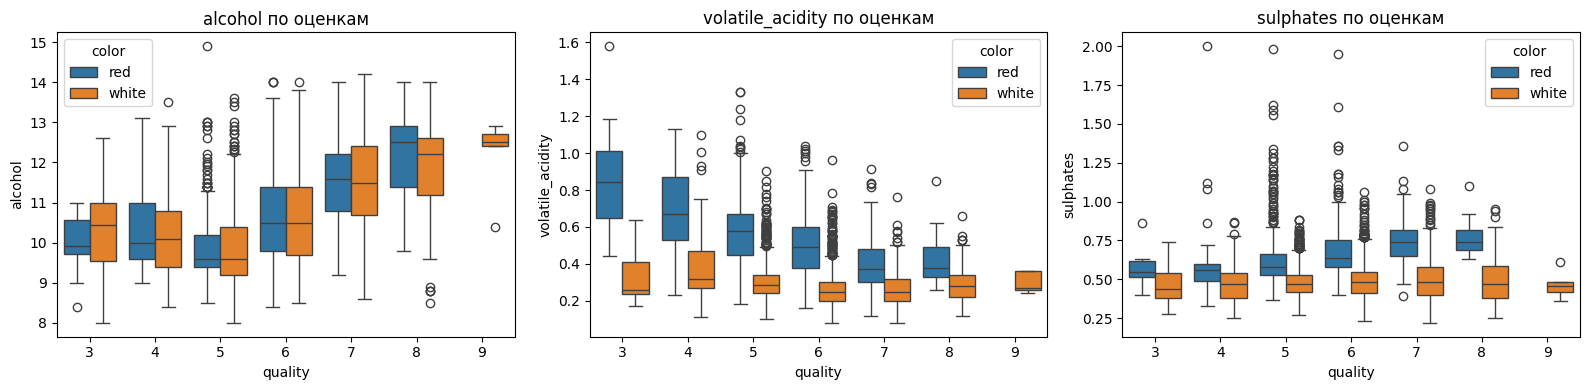

In [141]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['alcohol', 'volatile_acidity', 'sulphates']):
    sns.boxplot(data=df, x='quality', y=col, hue='color', ax=ax)
    ax.set_title(f'{col} по оценкам')
plt.tight_layout()
plt.show()

Вывод. Медианное содержание алкоголя почти не различается у вин с оценками 3–5, но уверенно растёт для оценок 6–8: зависимость нелинейная, и алкоголь в основном отличает хорошие вина от средних, а не средние от плохих. Картина одинакова для красных и белых вин. При этом распределения соседних оценок сильно перекрываются, поэтому по одному алкоголю качество предсказать нельзя.

Летучая кислотность у красных вин монотонно снижается с ростом оценки (медиана от ~0,85 при оценке 3 до ~0,4 при оценке 8), а у белых почти не меняется. Вероятно, она ухудшает вкус лишь при высоком уровне, которого белые вина практически не достигают. Сульфаты растут с оценкой только у красных вин, у белых связь отсутствует.

Графики подтверждают выводы из корреляционного анализа: влияние ряда признаков зависит от цвета вина, а часть связей нелинейна. Для линейной модели это означает необходимость признаков взаимодействия с цветом или отдельных моделей; модели на основе деревьев способны уловить такие зависимости автоматически.

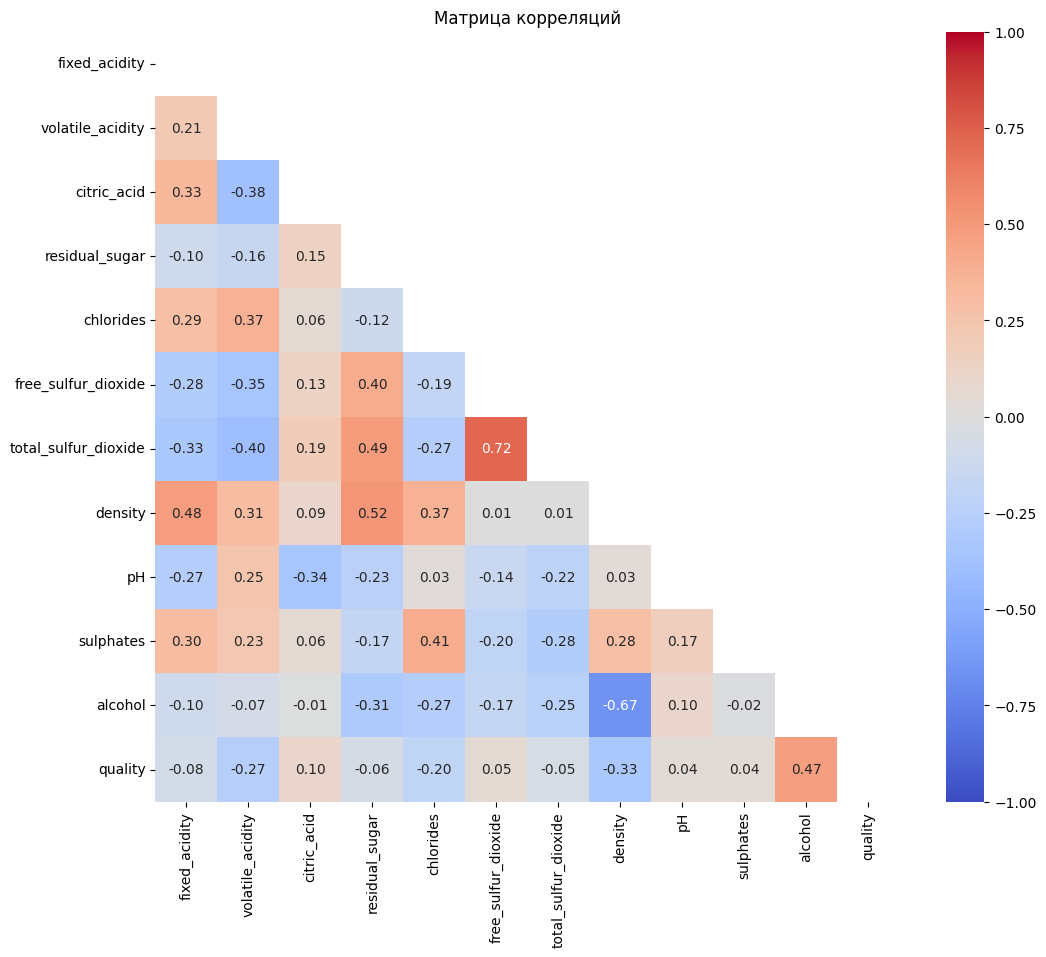

In [142]:
corr = df[list(features) + ['quality']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Матрица корреляций')
plt.show()

Вывод. Самая сильная связь между признаками — у свободного и общего диоксида серы (r = 0,72): свободный SO₂ входит в общий по определению. Плотность сильно связана с алкоголем (−0,67), сахаром (+0,52) и фиксированной кислотностью (+0,48), то есть во многом определяется другими признаками. Её корреляция с качеством (−0,33), вероятно, в основном отражает влияние алкоголя. Отрицательная связь pH с кислотами согласуется с химией вина и подтверждает осмысленность данных. Значительная часть корреляций между признаками объясняется различием красных и белых вин: «красные» признаки (летучая кислотность, хлориды, сульфаты) положительно связаны между собой и отрицательно — с «белыми» (диоксид серы, сахар).

Мультиколлинеарность умеренная (максимум |r| = 0,72). Для деревьев и бустинга она не важна; для линейных моделей сделает коэффициенты неустойчивыми, поэтому будем использовать Ridge-регуляризацию и проверим, улучшит ли модель удаление density или замена пары признаков SO₂ на связанный SO₂ и долю свободного.

Итоги первичного анализа

Данные. 6497 вин, после удаления 1177 дубликатов (они вызвали бы утечку между обучающей и тестовой выборками) осталось 5320. Пропусков нет, все признаки числовые, кроме color, который нужно закодировать.

Целевая переменная. Оценки от 3 до 9, около 77% вин получили 5 или 6. Модель будет склонна предсказывать средние оценки и хуже справляться с крайними, поэтому при разбиении используем стратификацию, а ошибку анализируем отдельно по оценкам. Задачу решаем как регрессию, базовый уровень ошибки — std качества ≈ 0,88.

Предобработка для линейных моделей. Признаки имеют сильно разные масштабы — нужна стандартизация. Шесть признаков сильно скошены вправо (chlorides, sulphates, residual_sugar, fixed_acidity, volatile_acidity, free_sulfur_dioxide) — применим log1p. Экстремальные значения единичны и в основном физически правдоподобны, их не удаляем. Все преобразования настраиваются только на обучающей выборке внутри Pipeline.

Значимые признаки. Сильнее всего с качеством связан алкоголь (r ≈ 0,47), причём связь нелинейная: он в основном отличает хорошие вина от средних. Летучая кислотность и сульфаты важны преимущественно для красных вин.

Роль цвета. Красные и белые вина различаются почти по всем признакам, а влияние ряда признаков на качество зависит от цвета, вплоть до смены знака; на объединённых данных некоторые связи маскируются (парадокс Симпсона для общего SO₂). Поэтому признаки нельзя отбирать по общей корреляции, а модель должна учитывать взаимодействие с цветом: через отдельные модели для красных и белых, признаки взаимодействия или деревья и бустинг.

Ожидания. Ни один признак не связан с качеством сильно, мультиколлинеарность умеренная. Стоит ожидать умеренной точности предсказания субъективной экспертной оценки; ключевым ориентиром будет превосходство над базовой моделью, предсказывающей среднее.

Начнем обучение моделей! Для начала создам baseline, который просто каждый раз будет предсказывать мат ожидание train выборки.

In [143]:
from sklearn.model_selection import train_test_split

X = df.drop(columns='quality')
X['is_red'] = (X.pop('color') == 'red').astype(int)   # кодируем цвет в 0/1
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Разбиение. Данные (5320 вин после удаления дубликатов) разделены на обучающую (80%, ≈4256 вин) и тестовую (20%, ≈1064 вина) части с random_state=42. Пропорция 80/20 даёт достаточно данных для обучения и при этом около тысячи объектов в тесте, чтобы оценка RMSE была устойчивой. Использована стратификация по quality: оценки сильно несбалансированы, и при простом случайном разбиении редкие оценки (3, 8, 9) могли бы почти целиком оказаться в одной части. Дубликаты удалены до разбиения, чтобы одинаковые вина не попали одновременно в train и test.

Почему нельзя многократно оценивать модели на тесте. Если сравнивать много вариантов моделей, признаков и параметров по тестовой выборке и выбирать лучший, то выбор неявно подстраивается под конкретные объекты теста. Тестовая ошибка лучшей модели становится оптимистично смещённой, то есть перестаёт быть честной оценкой качества на новых данных. По сути тест превращается во вторую обучающую выборку. Поэтому выбор моделей и гиперпараметров делаем по кросс-валидации на train, а тест используем один раз, для финальной оценки.

In [144]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)          # запоминает среднее y_train
y_pred = baseline.predict(X_test)       # для всех вин одно и то же число

print('Предсказание:', y_pred[0])
print('MAE :', mean_absolute_error(y_test, y_pred))
print('RMSE:', mean_squared_error(y_test, y_pred) ** 0.5)

Предсказание: 5.795347744360902
MAE : 0.694789576149019
RMSE: 0.8801023384558065


Для основной метрики RMSE оптимальная константа — среднее целевой переменной: минимум $\sum (y_i - c)^2$ по $c$ достигается при $c = \bar{y}$ (производная $-2\sum (y_i - c) = 0$). Для MAE оптимальной была бы медиана. Среднее считается только по обучающей выборке, иначе в baseline просочилась бы информация из теста.

Вывод. Базовая модель для любого вина предсказывает среднюю оценку обучающей выборки (≈ 5,80) и не использует признаки. Её ошибка на тестовой выборке: MAE ≈ 0,69, RMSE ≈ 0,88, что совпадает со стандартным отклонением качества. RMSE заметно больше MAE, потому что сильнее штрафует крупные ошибки, а их baseline допускает на винах с крайними оценками. Любая полезная модель должна давать ошибку заметно ниже этих значений.

MAE — средний модуль ошибки: на сколько баллов в среднем промахивается модель. Все ошибки входят линейно, и метрику легко интерпретировать в единицах оценки.
RMSE — корень из среднего квадрата ошибки, тоже в баллах. Показывает типичный размер ошибки с повышенным вниманием к крупным промахам.
Почему RMSE сильнее реагирует на большие ошибки: ошибки возводятся в квадрат. Ошибка в 2 балла даёт вклад 4, а ошибка в 0,5 — всего 0,25, то есть в 16 раз меньше, хотя по модулю разница в 4 раза.
Почему MAE и RMSE могут заметно различаться: всегда RMSE ≥ MAE, и разрыв тем больше, чем неравномернее ошибки. Если модель ошибается понемногу на большинстве объектов и сильно на немногих, крупные промахи раздувают RMSE, почти не меняя MAE. У нас это вина с редкими оценками 3, 4, 8, 9: на них модель ошибается на 1–3 балла.

Теперь создам две модели линейной регрессии - первая с 'сырыми' данными - вторая после логарифмирования и стандартизации признаков. Так же для начала создам функцию, которая принимает обученную модель, считает ошибки на тестовых данных и кладет результаты в массив results. 

In [145]:
results = []

def evaluate(name, model):
    y_pred = model.predict(X_test)
    results.append({
        'model': name,
        'MAE':  mean_absolute_error(y_test, y_pred),
        'RMSE': mean_squared_error(y_test, y_pred) ** 0.5,
    })
    return pd.DataFrame(results)

evaluate('Baseline (mean)', baseline)

,model,MAE,RMSE
0,Baseline (mean),0.69479,0.880102


Голая регрессия

In [146]:
from sklearn.linear_model import LinearRegression

lr_raw = LinearRegression()
lr_raw.fit(X_train, y_train)
evaluate('LinearRegression (raw)', lr_raw)

,model,MAE,RMSE
0,Baseline (mean),0.694790,0.880102
1,LinearRegression (raw),0.566001,0.729242


Регрессия + Стандартизация

In [147]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

lr_scaled = make_pipeline(StandardScaler(), LinearRegression())
lr_scaled.fit(X_train, y_train)
evaluate('LinearRegression + scaling', lr_scaled)

,model,MAE,RMSE
0,Baseline (mean),0.694790,0.880102
1,LinearRegression (raw),0.566001,0.729242
2,LinearRegression + scaling,0.566001,0.729242


Ошибки идентичные, ведь линейная регрессия ищет веса через уравнение.(метод наименьших квадратов)

 Коэффициенты линейной регрессии на исходных данных нельзя сравнивать по модулю: коэффициент показывает изменение оценки при изменении признака на одну единицу, а единица плотности (≈ весь диапазон признака) и единица диоксида серы (крошечная доля диапазона) несопоставимы. После стандартизации коэффициент означает изменение прогноза при изменении признака на одно стандартное отклонение, и тогда их уже можно сравнивать между собой. На качество прогноза обычной линейной регрессии масштабирование не влияет (метрики совпали), но для регуляризованной модели (Ridge) оно обязательно.

Регрессия + Стандартизация + Регуляризация(Ridge) + Логарифм

In [148]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import RidgeCV

skewed = ['chlorides', 'sulphates', 'residual_sugar',
          'fixed_acidity', 'volatile_acidity', 'free_sulfur_dioxide']
other = [c for c in X.columns if c not in skewed + ['is_red']]

preprocess = ColumnTransformer([
    ('log_scale', make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), skewed),
    ('scale',     StandardScaler(), other),
], remainder='passthrough')

ridge = make_pipeline(preprocess, RidgeCV(alphas=np.logspace(-3, 3, 50)))
ridge.fit(X_train, y_train)
print('Лучшее alpha:', ridge[-1].alpha_)
evaluate('Ridge + log + scaling', ridge)

Лучшее alpha: 104.81131341546852


,model,MAE,RMSE
0,Baseline (mean),0.694790,0.880102
1,LinearRegression (raw),0.566001,0.729242
2,LinearRegression + scaling,0.566001,0.729242
3,Ridge + log + scaling,0.562313,0.723788


Коэффициенты Ridge:

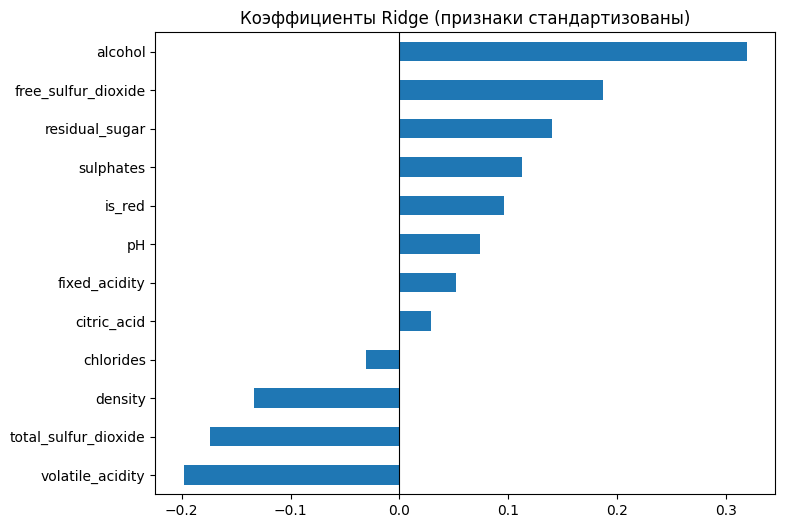

In [149]:
feature_names = skewed + other + ['is_red']
coefs = pd.Series(ridge[-1].coef_, index=feature_names).sort_values()

coefs.plot(kind='barh', figsize=(8, 6))
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Коэффициенты Ridge (признаки стандартизованы)')
plt.show()

Вывод. Линейная регрессия снижает ошибку относительно базовой модели примерно на 18% (MAE 0,566 против 0,695, RMSE 0,729 против 0,880) и объясняет около трети разброса оценок (R² ≈ 0,31). Стандартизация без регуляризации не изменила результат, как и ожидалось: коэффициенты линейной регрессии компенсируют масштаб признаков. Логарифмирование и Ridge-регуляризация (α ≈ 105) дали лишь незначительное улучшение (MAE 0,562), сопоставимое со случайными колебаниями. Следовательно, качество ограничено не предобработкой, а линейной формой модели, которая не учитывает нелинейные зависимости и различие влияния признаков для красных и белых вин.

Наибольший положительный вклад вносит алкоголь, наибольший отрицательный — летучая кислотность, что согласуется с EDA. Свободный и общий диоксид серы получили противоположные по знаку коэффициенты: при одинаковом общем SO₂ рост свободного означает снижение связанного, то есть модель указывает на негативное влияние именно связанного SO₂. Положительный коэффициент сахара при отрицательной корреляции с качеством объясняется мультиколлинеарностью с плотностью и алкоголем, поэтому коэффициенты связанных признаков нельзя интерпретировать изолированно.

Продолжим моделирование уже с такими моделями как дерево, случайный лес и градиентный бустинг. Обучим их на обычных, не предобработанных данных, так как деревьям не нужна стандартизация и отбор признаков(в моем случае).

In [150]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

def train_test_mae(model):
    mae_train = mean_absolute_error(y_train, model.predict(X_train))
    mae_test  = mean_absolute_error(y_test,  model.predict(X_test))
    print(f'MAE train: {mae_train:.3f} | MAE test: {mae_test:.3f}')

In [151]:
# Без ограничений: дерево растёт, пока не запомнит train
tree_full = DecisionTreeRegressor(random_state=42)
tree_full.fit(X_train, y_train)
print('Глубина:', tree_full.get_depth(), '| Листьев:', tree_full.get_n_leaves())
train_test_mae(tree_full)
evaluate('DecisionTree (без ограничений)', tree_full)

# С ограничением глубины
tree_5 = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_5.fit(X_train, y_train)
train_test_mae(tree_5)
evaluate('DecisionTree (max_depth=5)', tree_5)

Глубина: 26 | Листьев: 1375
MAE train: 0.000 | MAE test: 0.683
MAE train: 0.546 | MAE test: 0.572


,model,MAE,RMSE
0,Baseline (mean),0.694790,0.880102
1,LinearRegression (raw),0.566001,0.729242
2,LinearRegression + scaling,0.566001,0.729242
3,Ridge + log + scaling,0.562313,0.723788
4,DecisionTree (без ограничений),0.683271,0.977664
5,DecisionTree (max_depth=5),0.572312,0.737425


Вывод. Дерево без ограничений выросло до глубины 26 и 1375 листьев (в среднем около трёх вин на лист) и полностью запомнило обучающую выборку: MAE на train равна 0. На тестовой выборке его ошибка (MAE 0,683) почти равна базовой модели, а RMSE (0,978) даже хуже, чем у предсказания среднего. Переобученное дерево выдаёт «уверенные» прогнозы из маленьких листьев и при ошибке промахивается сразу на несколько баллов, что сильно штрафуется квадратичной метрикой. Ограничение глубины до 5 устраняет переобучение (MAE 0,546 на train и 0,572 на test), но одиночное дерево с не более чем 32 листьями даёт слишком грубое ступенчатое приближение и по качеству лишь сопоставимо с линейной регрессией. Это мотивирует переход к ансамблям деревьев.

In [152]:
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
train_test_mae(rf)
evaluate('RandomForest (default)', rf)

MAE train: 0.194 | MAE test: 0.531


,model,MAE,RMSE
0,Baseline (mean),0.694790,0.880102
1,LinearRegression (raw),0.566001,0.729242
2,LinearRegression + scaling,0.566001,0.729242
3,Ridge + log + scaling,0.562313,0.723788
4,DecisionTree (без ограничений),0.683271,0.977664
5,DecisionTree (max_depth=5),0.572312,0.737425
6,RandomForest (default),0.530733,0.686250


Вывод. Случайный лес из 300 деревьев показал лучший результат среди рассмотренных моделей: MAE 0,531 и RMSE 0,686 на тестовой выборке, что примерно на 5% лучше Ridge-регрессии и на 22–24% лучше базовой модели (R² ≈ 0,39). Одиночное неограниченное дерево давало на тесте ошибку почти как у базовой модели, а усреднение 300 таких же деревьев, обученных на бутстрэп-выборках со случайными подмножествами признаков, снизило её с 0,683 до 0,531: ошибки отдельных деревьев в значительной степени взаимно компенсируются. Большой разрыв между ошибкой на train (0,194) и test для леса ожидаем, так как деревья глубокие, и не свидетельствует о плохом обобщении. Преимущество над линейной моделью подтверждает вывод EDA о важности нелинейных зависимостей и взаимодействий признаков, однако оно умеренное: экспертная оценка лишь частично определяется физико-химическими показателями.

In [153]:
gb = HistGradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)
train_test_mae(gb)
evaluate('GradientBoosting (default)', gb)

MAE train: 0.372 | MAE test: 0.534


,model,MAE,RMSE
0,Baseline (mean),0.694790,0.880102
1,LinearRegression (raw),0.566001,0.729242
2,LinearRegression + scaling,0.566001,0.729242
3,Ridge + log + scaling,0.562313,0.723788
4,DecisionTree (без ограничений),0.683271,0.977664
5,DecisionTree (max_depth=5),0.572312,0.737425
6,RandomForest (default),0.530733,0.686250
7,GradientBoosting (default),0.534066,0.691977


Вывод. Градиентный бустинг с параметрами по умолчанию показал качество, практически равное случайному лесу (MAE 0,534 против 0,531, RMSE 0,692 против 0,686); различие находится в пределах случайных колебаний и не позволяет выделить лучшую модель. Разрыв между ошибкой на train и test у бустинга меньше, поскольку он строит неглубокие деревья с небольшим шагом обучения, а обучается он примерно в 30 раз быстрее леса. То, что два принципиально разных ансамблевых метода дают почти одинаковую ошибку, указывает на приближение к пределу предсказуемости экспертной оценки по физико-химическим признакам. Бустинг чувствительнее к гиперпараметрам, поэтому от их подбора для него можно ожидать большего эффекта, чем для леса.

Подберем гиперпараметры через Grid Search.

In [154]:
from sklearn.model_selection import GridSearchCV, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

def run_grid(name, model, param_grid):
    gs = GridSearchCV(model, param_grid, cv=cv,
                      scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_train, y_train)
    print(name)
    print('  лучшие параметры:', gs.best_params_)
    print(f'  RMSE на кросс-валидации: {-gs.best_score_:.3f}')
    train_test_mae(gs.best_estimator_)
    return gs
RUN_GRID = False

In [155]:
if RUN_GRID:
    gs_tree = run_grid('DecisionTree (GridSearch)',
        DecisionTreeRegressor(random_state=42),
        {
            'max_depth':        [3, 5, 7, 10, 15, None],
            'min_samples_leaf': [1, 5, 10, 20, 50],
        })

In [156]:
if RUN_GRID:
    gs_rf = run_grid('RandomForest (GridSearch)',
        RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
        {
            'max_features':     [0.33, 0.5, 1.0],
            'min_samples_leaf': [1, 3, 5],
            'max_depth':        [None, 20],
        })

In [157]:
if RUN_GRID:
    gs_gb = run_grid('GradientBoosting (GridSearch)',
        HistGradientBoostingRegressor(random_state=42),
        {
            'learning_rate':    [0.03, 0.1],
            'max_iter':         [200, 500],
            'max_depth':        [3, 6, None],
            'min_samples_leaf': [10, 20],
        })

Подбор гиперпараметров выполнен через GridSearchCV на 5-кратной кросс-валидации внутри обучающей выборки по основной метрике RMSE. Лучшие параметры: дерево — max_depth=5, min_samples_leaf=5 (RMSE на CV 0,757); случайный лес — max_features=0.33, min_samples_leaf=1, max_depth=None (0,687); бустинг — learning_rate=0.03, max_iter=200, max_depth=None, min_samples_leaf=20 (0,697). Лучшая модель выбрана по RMSE на кросс-валидации — это случайный лес. Тестовая выборка в подборе и выборе модели не участвовала.

In [158]:
tree_best = DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=42)
tree_best.fit(X_train, y_train)
evaluate('DecisionTree (tuned)', tree_best)

rf_best = RandomForestRegressor(n_estimators=300, max_features=0.33, min_samples_leaf=1,
                                max_depth=None, random_state=42, n_jobs=-1)
rf_best.fit(X_train, y_train)
train_test_mae(rf_best)
evaluate('RandomForest (tuned)', rf_best)

gb_best = HistGradientBoostingRegressor(learning_rate=0.03, max_iter=200, max_depth=None,
                                        min_samples_leaf=20, random_state=42)
gb_best.fit(X_train, y_train)
train_test_mae(gb_best)
evaluate('GradientBoosting (tuned)', gb_best)

MAE train: 0.193 | MAE test: 0.526
MAE train: 0.421 | MAE test: 0.532


,model,MAE,RMSE
0,Baseline (mean),0.694790,0.880102
1,LinearRegression (raw),0.566001,0.729242
2,LinearRegression + scaling,0.566001,0.729242
3,Ridge + log + scaling,0.562313,0.723788
4,DecisionTree (без ограничений),0.683271,0.977664
5,DecisionTree (max_depth=5),0.572312,0.737425
6,RandomForest (default),0.530733,0.686250
7,GradientBoosting (default),0.534066,0.691977
8,DecisionTree (tuned),0.567266,0.733003
9,RandomForest (tuned),0.525611,0.679808


Выведу топ моделей, сортируя по RMSE.

In [159]:
final = pd.DataFrame(results)[['model', 'RMSE', 'MAE']].sort_values('RMSE').reset_index(drop=True)
display(final.round(3))

,model,RMSE,MAE
0,RandomForest (tuned),0.680,0.526
1,RandomForest (default),0.686,0.531
2,GradientBoosting (tuned),0.689,0.532
3,GradientBoosting (default),0.692,0.534
4,Ridge + log + scaling,0.724,0.562
5,LinearRegression + scaling,0.729,0.566
6,LinearRegression (raw),0.729,0.566
7,DecisionTree (tuned),0.733,0.567
8,DecisionTree (max_depth=5),0.737,0.572
9,Baseline (mean),0.880,0.695


In [160]:
best = rf_best
y_pred_best = best.predict(X_test)

errors = pd.DataFrame({
    'true':  y_test.values,
    'pred':  y_pred_best,
    'color': np.where(X_test['is_red'].values == 1, 'red', 'white'),
})
errors['abs_error'] = (errors['true'] - errors['pred']).abs()
errors['bias'] = errors['pred'] - errors['true']

by_quality = errors.groupby('true').agg(
    count=('abs_error', 'size'),
    mean_pred=('pred', 'mean'),
    mae=('abs_error', 'mean'),
    mean_bias=('bias', 'mean'),
)
display(by_quality.round(3))
display(errors.groupby('color')['abs_error'].agg(['size', 'mean']).round(3))

,count,mean_pred,mae,mean_bias
true,,,,
3,6,5.368,2.368,2.368
4,41,5.230,1.230,1.230
5,350,5.426,0.433,0.426
6,465,5.841,0.386,-0.159
7,171,6.335,0.666,-0.665
8,30,6.450,1.550,-1.550
9,1,5.557,3.443,-3.443


,size,mean
color,,
red,267,0.454
white,797,0.549


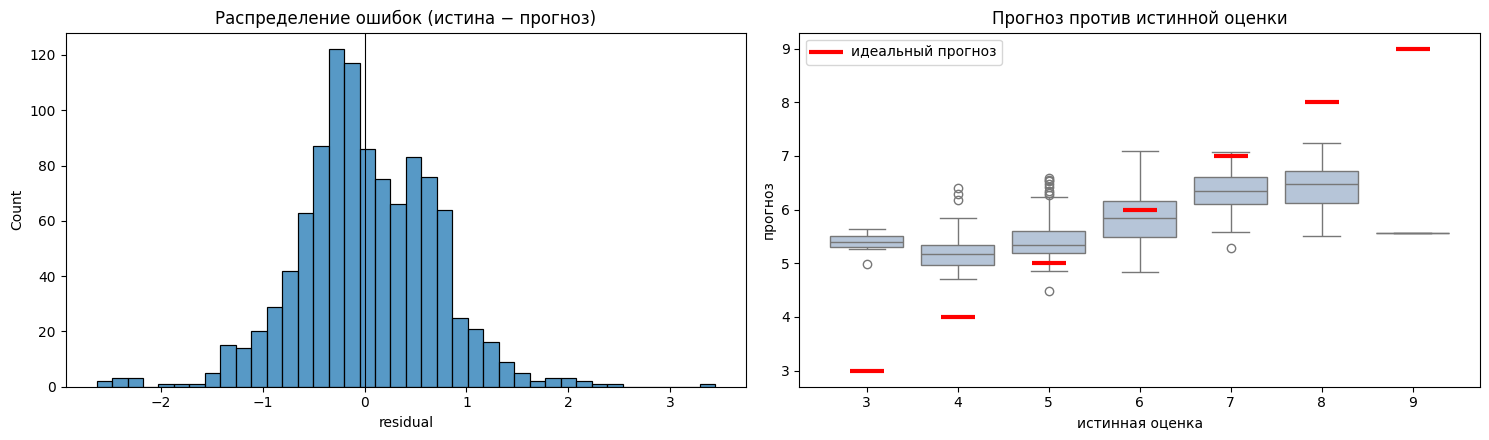

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,true,pred
2012,9.1,0.270,0.45,10.60,0.035,28.0,124.0,0.99700,3.20,0.46,10.4,0,9,5.56
1982,6.9,0.390,0.40,4.60,0.022,5.0,19.0,0.99150,3.31,0.37,12.6,0,3,5.63
1571,8.5,0.260,0.21,16.20,0.074,41.0,197.0,0.99800,3.02,0.50,9.8,0,3,5.53
2549,8.2,0.220,0.36,6.80,0.034,12.0,90.0,0.99440,3.01,0.38,10.5,0,8,5.52
2783,6.7,0.250,0.26,1.55,0.041,118.5,216.0,0.99490,3.55,0.63,9.4,0,3,5.42
4984,5.8,0.260,0.30,2.60,0.034,75.0,129.0,0.99020,3.20,0.38,11.5,0,4,6.41
1165,6.8,0.815,0.00,1.20,0.267,16.0,29.0,0.99471,3.32,0.51,9.8,1,3,5.38
3881,7.0,0.530,0.43,6.10,0.029,6.0,76.0,0.99118,3.08,0.50,12.5,0,8,5.70
4158,6.7,0.640,0.30,1.20,0.030,18.0,76.0,0.98920,3.16,0.60,12.9,0,4,6.29
1245,7.3,0.980,0.05,2.10,0.061,20.0,49.0,0.99705,3.31,0.55,9.7,1,3,5.27


,alcohol,volatile_acidity,sulphates,free_sulfur_dioxide
quality,,,,
3,10.15,0.42,0.50,17.0
4,10.10,0.38,0.49,15.0
5,9.60,0.34,0.51,27.0
6,10.50,0.27,0.52,29.0
7,11.50,0.28,0.52,29.0
8,12.20,0.28,0.49,32.0
9,12.50,0.27,0.46,28.0


In [161]:
errors['residual'] = errors['true'] - errors['pred']

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(errors['residual'], bins=40, ax=axes[0])
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Распределение ошибок (истина − прогноз)')

levels = sorted(errors['true'].unique())
sns.boxplot(data=errors, x='true', y='pred', color='lightsteelblue', ax=axes[1])
axes[1].scatter(range(len(levels)), levels, color='red', marker='_', s=600,
                linewidths=3, zorder=3, label='идеальный прогноз')
axes[1].set_xlabel('истинная оценка'); axes[1].set_ylabel('прогноз')
axes[1].set_title('Прогноз против истинной оценки')
axes[1].legend()
plt.tight_layout(); plt.show()

# 10 вин с самыми большими ошибками
worst = errors.sort_values('abs_error', ascending=False).head(10)
worst_wines = X_test.iloc[worst.index].assign(
    true=worst['true'].values, pred=worst['pred'].round(2).values)
display(worst_wines)

# типичные значения признаков для каждой оценки — для сравнения
display(df.groupby('quality')[['alcohol', 'volatile_acidity', 'sulphates',
                                'free_sulfur_dioxide']].median().round(2))

Распределение ошибок. Ошибки сосредоточены около нуля: подавляющее большинство вин предсказано с точностью ±1 балл. Распределение имеет два пика (около −0,3 и +0,6), потому что истинные оценки целые, а прогнозы непрерывные и сжаты к 5,4–6: вина с оценкой 5 модель слегка переоценивает, с оценками 6–7 недооценивает. Хвосты тянутся до ±2,5, отдельная ошибка +3,4 — единственное вино с оценкой 9. График «прогноз против истины» показывает, что прогнозы почти никогда не выходят за пределы 5–7: для вин с оценками 3 и 4 медианный прогноз около 5,2–5,4 (для оценки 4 даже ниже, чем для 3), для оценки 8 — около 6,5.

Вина с наибольшими ошибками. Девять из десяти худших прогнозов приходятся на редкие оценки 3, 4, 8 и 9, причём модель всегда тянет прогноз к середине шкалы. Можно выделить три типа причин:

Химически «обычные» вина с крайней оценкой. Вино с оценкой 9 (прогноз 5,56) имеет 10,4% алкоголя и средние значения остальных признаков — по составу оно похоже на типичное вино с оценкой 5–6 (медиана алкоголя для оценки 9 — 12,5%). Аналогично вино с оценкой 8 (прогноз 5,52) с 10,5% алкоголя. Вероятно, высокая оценка определяется факторами, которых нет в данных: аромат, сорт винограда, выдержка, — либо субъективностью дегустаторов.
Противоречивые признаки. Вина с оценкой 4 (прогнозы 6,41 и 6,29) крепкие (11,5% и 12,9%), что модель связывает с хорошими винами, но у второго очень высокая летучая кислотность (0,64 при медиане 0,38 для оценки 4), дающая уксусный привкус. Вино с оценкой 8 (прогноз 5,70) крепкое (12,5%), но тоже с высокой для белого вина летучей кислотностью (0,53). Модель усредняет разнонаправленные сигналы и выдаёт среднюю оценку, тогда как реальное восприятие определяется одним доминирующим дефектом или достоинством.
Явные признаки плохого вина, которые модель недооценивает. Красные вина с оценкой 3 имеют экстремальную летучую кислотность (0,815 и 0,98) и, у одного из них, очень высокие хлориды (0,267), но модель всё равно предсказывает 5,3–5,4. Белое вино с оценкой 3 имеет избыток свободного SO₂ (118,5), другое — почти полное его отсутствие (5), что согласуется с гипотезой о немонотонном влиянии SO₂.

Почему редкие оценки предсказываются хуже. В обучающей выборке всего около 24 вин с оценкой 3 и 4 вина с оценкой 9. В листьях деревьев такие вина оказываются вместе с множеством вин с оценками 5–6, и прогноз листа — среднее — сдвигается к середине. Кроме того, модель минимизирует общую квадратичную ошибку, а её основной вклад дают частые оценки, поэтому подстраиваться под редкие вина ей невыгодно. Наконец, разнообразие «плохих» и «отличных» вин велико (они плохи или хороши по разным причинам), и нескольких десятков примеров недостаточно, чтобы выучить эти закономерности.

Посмотрим теперь на Permutation importance (важность через перестановку).

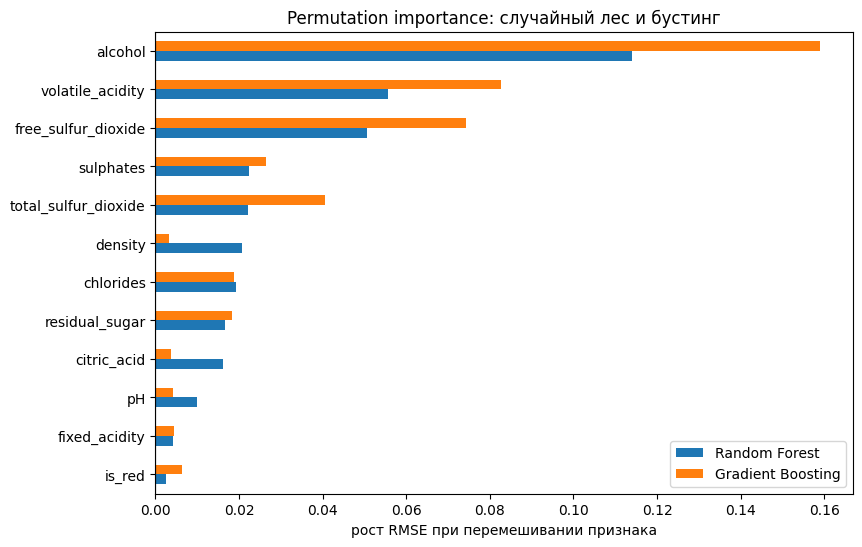

,Random Forest,Gradient Boosting,RF встроенная (MDI),Ridge |коэф.|,|корр. с quality|
alcohol,1,1,1,1,1
volatile_acidity,2,2,3,2,3
free_sulfur_dioxide,3,3,4,3,8
sulphates,4,5,7,7,10
total_sulfur_dioxide,5,4,6,4,9
density,6,12,2,6,2
chlorides,7,6,5,11,4
residual_sugar,8,7,8,5,7
citric_acid,9,11,10,12,5
pH,10,10,9,9,11


In [162]:
from sklearn.inspection import permutation_importance

imp = {}
for name, m in [('Random Forest', rf_best), ('Gradient Boosting', gb_best)]:
    r = permutation_importance(m, X_test, y_test, n_repeats=5, random_state=42,
                               scoring='neg_root_mean_squared_error', n_jobs=1)
    imp[name] = r.importances_mean
imp = pd.DataFrame(imp, index=X_test.columns)

imp.sort_values('Random Forest').plot(kind='barh', figsize=(9, 6))
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('рост RMSE при перемешивании признака')
plt.title('Permutation importance: случайный лес и бустинг')
plt.show()

# сводная таблица рангов: 1 — самый важный признак
compare = imp.copy()
compare['RF встроенная (MDI)'] = pd.Series(rf_best.feature_importances_, index=X_train.columns)
compare['Ridge |коэф.|'] = coefs.abs()                 # coefs из ячейки с графиком Ridge
compare['|корр. с quality|'] = df[features].corrwith(df['quality']).abs()
display(compare.rank(ascending=False).sort_values('Random Forest').astype('Int64'))

Сравнение важности признаков. Случайный лес и градиентный бустинг выделяют одну и ту же тройку наиболее важных признаков: алкоголь, летучая кислотность и свободный диоксид серы. Для обеих моделей алкоголь — безусловный лидер: при его перемешивании RMSE растёт на 0,11 у леса и на 0,16 у бустинга. Эта же тройка лидирует и по модулю коэффициентов Ridge-регрессии. Алкоголь и летучая кислотность согласуются с EDA (самые сильные связи с качеством, причём летучая кислотность особенно важна для красных вин).

Главное расхождение с корреляционным анализом — свободный SO₂: по корреляции с качеством он лишь 8-й, а для всех моделей — 3-й. Его связь с качеством немонотонна (вредны и недостаток, и избыток, что видно и среди вин с наибольшими ошибками), поэтому линейный коэффициент корреляции её не улавливает, а деревья улавливают. Обратная ситуация у плотности и лимонной кислоты: по корреляции они 2-я и 5-я, но для моделей малозначимы. Их связь с качеством опосредована: плотность почти полностью определяется алкоголем и сахаром, а лимонная кислота — различием красных и белых вин.

Различия между лесом и бустингом объясняются устройством алгоритмов. Бустинг почти не использует плотность (ранг 12), получая ту же информацию из алкоголя и сахара. Лес с max_features=0.33 при каждом разбиении видит лишь треть признаков и, когда алкоголь недоступен, вынужден использовать коррелированную с ним плотность, поэтому важность у него распределяется между связанными признаками равномернее. Встроенная MDI-важность леса ставит плотность на 2-е место: эта мера считается на обучающей выборке и завышает важность непрерывных признаков с большим числом уникальных значений (у плотности их 998), поэтому для выводов мы опираемся на permutation importance. Признак is_red малозначим для обеих моделей, так как цвет вина однозначно восстанавливается по другим признакам.

В итоге все подходы согласны в главном: качество вина в первую очередь связано с содержанием алкоголя, летучей кислотностью и уровнем свободного SO₂. Различия в остальных признаках отражают не их бесполезность, а то, что связанные признаки взаимозаменяемы и модели распределяют между ними важность по-разному.

Можно ли по feature importance утверждать, что признак — причина изменения качества? Нет. Важность показывает, насколько конкретная модель опирается на признак при прогнозе, то есть насколько он полезен для предсказания, а не то, что изменение признака вызовет изменение качества. Причины: (1) данные наблюдательные, а не экспериментальные, никто не менял алкоголь при прочих равных; (2) возможны общие скрытые факторы — сорт винограда, урожай, технология и цена, которых нет в данных (см. описание датасета), — влияющие и на признаки, и на оценку; (3) связанные признаки делят важность: плотность может быть «важна» лишь как отражение алкоголя и сахара, а цвет почти не важен только потому, что восстанавливается по другим признакам; (4) важность зависит от модели — лес и Ridge ранжируют признаки по-разному. Например, высокая важность алкоголя не означает, что если добавить в вино спирт, эксперты поставят ему более высокую оценку: крепость может быть следствием более зрелого винограда, который и улучшает вкус.

## Итоговое сравнение моделей (тестовая выборка)

| № | Модель | RMSE | MAE | Улучшение RMSE к baseline | Улучшение MAE к baseline | R² |
|---|---|---|---|---|---|---|
| 1 | **Random Forest (подобранный)** | **0,680** | **0,526** | **−22,7%** | **−24,3%** | **0,40** |
| 2 | Random Forest (по умолчанию) | 0,686 | 0,531 | −22,0% | −23,6% | 0,39 |
| 3 | Gradient Boosting (подобранный) | 0,689 | 0,532 | −21,7% | −23,4% | 0,39 |
| 4 | Gradient Boosting (по умолчанию) | 0,692 | 0,534 | −21,4% | −23,2% | 0,38 |
| 5 | Ridge + логарифм + стандартизация | 0,724 | 0,562 | −17,7% | −19,1% | 0,32 |
| 6 | Linear Regression (с масштабированием и без) | 0,729 | 0,566 | −17,2% | −18,6% | 0,31 |
| 7 | Дерево решений (подобранное) | 0,733 | 0,567 | −16,7% | −18,4% | 0,31 |
| 8 | Дерево решений (max_depth=5) | 0,737 | 0,572 | −16,3% | −17,7% | 0,30 |
| 9 | Baseline (среднее) | 0,880 | 0,695 | — | — | 0 |
| 10 | Дерево решений (без ограничений) | 0,978 | 0,683 | +11,1% | −1,7% | −0,24 |

R² рассчитан как $1 - (\text{RMSE}_\text{модели} / \text{RMSE}_\text{baseline})^2$ — доля разброса оценок, объяснённая моделью.

**Какие модели превзошли baseline.** По RMSE — все, кроме дерева без ограничений: оно переобучилось и из-за крупных промахов на отдельных винах ошибается сильнее, чем предсказание среднего. Порог RMSE < 0,70 проходят только ансамбли: случайный лес и градиентный бустинг.

Лучший результат показал случайный лес с подобранными гиперпараметрами: его ошибка примерно на 24% ниже базовой модели и на 6–7% ниже линейной регрессии. Ансамбли деревьев превосходят линейные модели за счёт способности учитывать нелинейные зависимости и взаимодействия признаков, наличие которых было выявлено в ходе EDA (различное влияние признаков для красных и белых вин, немонотонная роль свободного SO₂). При этом предобработка (логарифмирование, стандартизация) и подбор гиперпараметров дали лишь незначительное улучшение, а лес и бустинг показали почти одинаковое качество. Это говорит о том, что точность ограничена не выбором модели, а информативностью физико-химических признаков для предсказания субъективной экспертной оценки.

Главное ограничение модели — систематическое смещение прогнозов к середине шкалы. Ошибка для оценок 5–6 составляет около 0,4 балла, а для крайних оценок превышает 1–2 балла: модель переоценивает плохие вина и недооценивает отличные. Это прямое следствие сильного дисбаланса целевой переменной, обнаруженного на этапе анализа данных. Для улучшения работы на редких оценках можно было бы использовать взвешивание наблюдений при обучении или переформулировать задачу как классификацию по укрупнённым классам («плохое / среднее / хорошее»).